# 1D nutrient–phytoplankton model: runs and plots

Each section is one experiment, built from the same pieces:
`sim.run(...)` returns the data in memory (nothing is saved unless you ask), `plots.*` draws it,
and any parameter in `params.py` can be overridden in the call, e.g. `sim.run(SINKING_ENABLED=True)`.

| Section | Question |
|---|---|
| 1 | Baseline: growth + mixing only |
| 2 | What does phytoplankton sinking change? |
| 3 | What does self-shading change? |
| 4 | Does the splitting order behave as the theory says? (Lie vs Strang) |
| 5 | How deep must the column be? (bottom boundary) |
| 6 | Forcing: seasonal nutrient supply, seasonal light, storm pulses, a eutrophication trend |

In [1]:
import sys
MODEL_DIR = "new_workflow"            # folder that contains sim.py, params.py, forcings.py, plots.py
sys.path.append(MODEL_DIR)

import numpy as np
import matplotlib.pyplot as plt

import sim, plots
from forcings import sine, pulses, ramp, add

plt.rcParams["figure.figsize"] = (8, 4)
trapz = getattr(np, "trapezoid", None) or np.trapz       # depth integral

def dcm(res):
    """Depth and value of the phytoplankton maximum at every saved time."""
    k = res.P.argmax(axis=1)
    return res.depth[k], res.P[np.arange(len(k)), k]

## 1. Baseline: growth + mixing

Defaults from `params.py`: closed bottom (Neumann), no sinking, no shading, no forcing.
Watch the integrated N and P: nitrogen only enters or leaves through the boundaries.

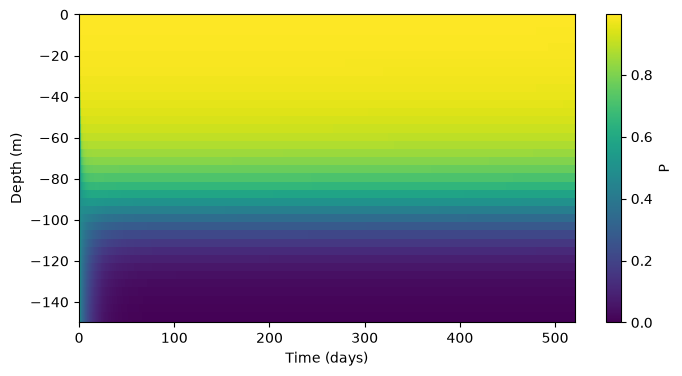

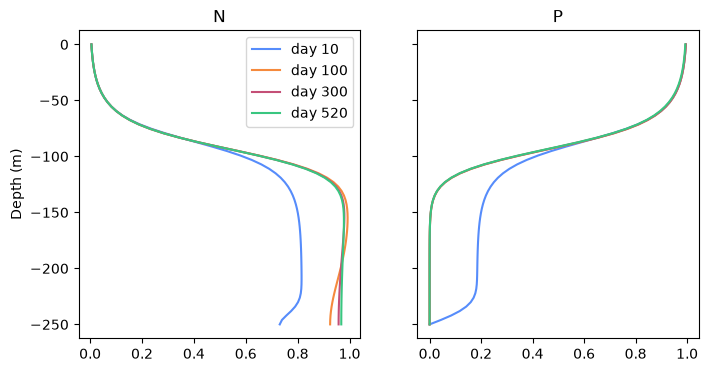

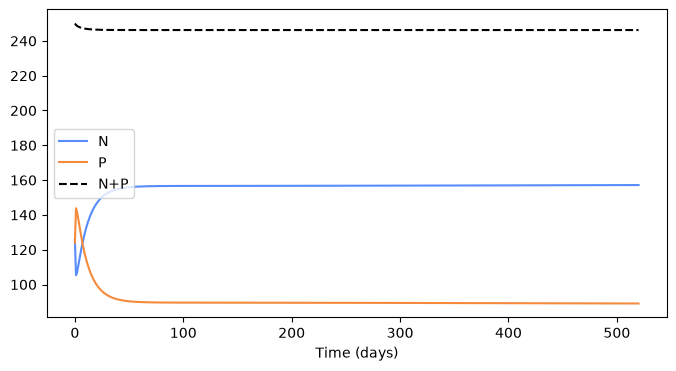

In [2]:
base = sim.run()
plots.hovmoller(base, "P", zmin=-150)
plots.profiles(base, [10, 100, 300, 520])
plots.integrated(base)
plt.show()

## 2. Phytoplankton sinking

Same run with `SINKING_ENABLED=True`. Compare where the phytoplankton maximum sits and how the profiles differ.

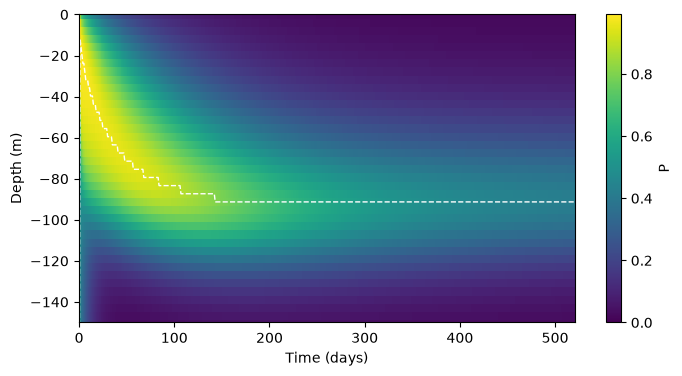

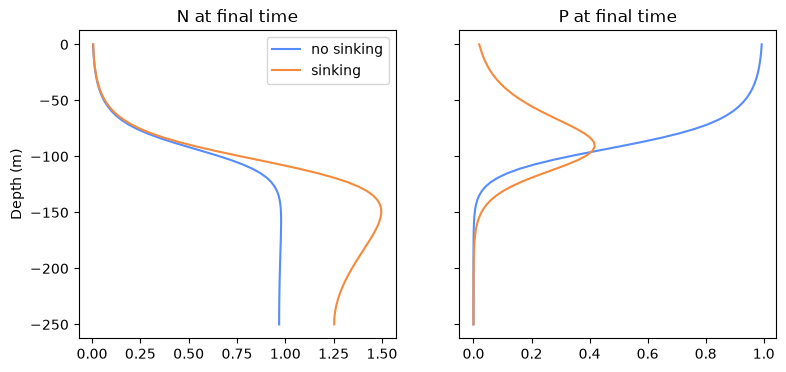

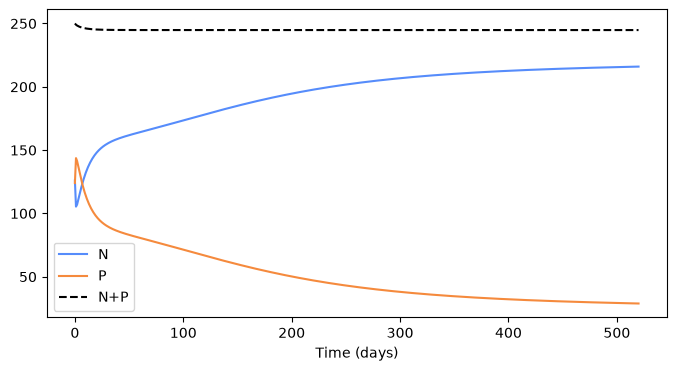

In [3]:
sink = sim.run(SINKING_ENABLED=True)

plots.hovmoller(sink, "P", zmin=-150)
d, v = dcm(sink)
plt.plot(sink.days, d, "w--", lw=1)                  # depth of the maximum

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(9, 4))
for res, name in ((base, "no sinking"), (sink, "sinking")):
    ax[0].plot(res.N[-1], res.depth, label=name)
    ax[1].plot(res.P[-1], res.depth, label=name)
ax[0].set_title("N at final time"); ax[1].set_title("P at final time")
ax[0].set_ylabel("Depth (m)"); ax[0].legend()
plots.integrated(sink)
plt.show()

## 3. Self-shading

`SHADING_ENABLED=True` uses the *local* formula `exp((K + SHADING_COEFF·P)·z)` (your current implementation),
not the Shigesada & Okubo integral over the P above each depth. Keep that distinction in mind when presenting.

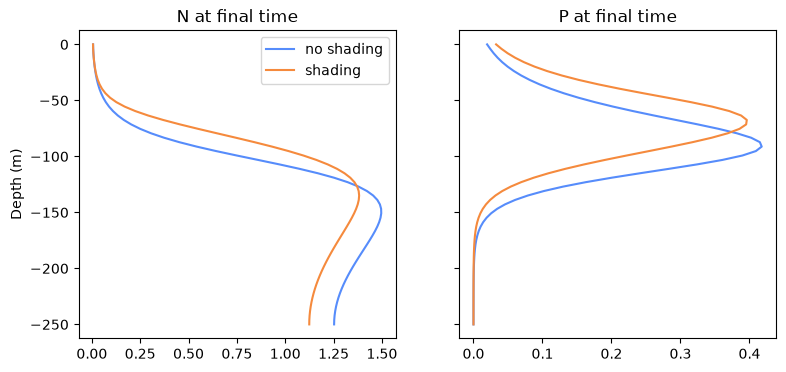

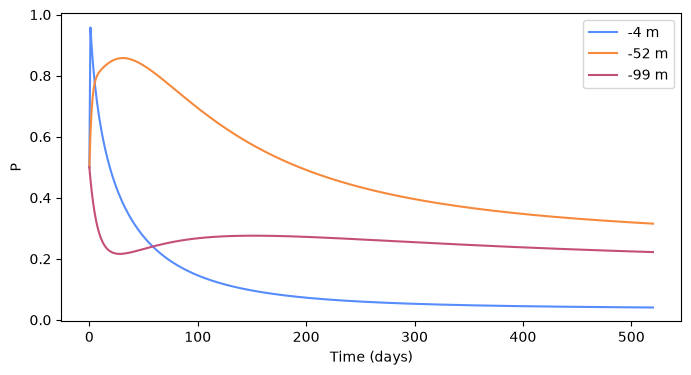

In [4]:
shade = sim.run(SINKING_ENABLED=True, SHADING_ENABLED=True)

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(9, 4))
for res, name in ((sink, "no shading"), (shade, "shading")):
    ax[0].plot(res.N[-1], res.depth, label=name)
    ax[1].plot(res.P[-1], res.depth, label=name)
ax[0].set_title("N at final time"); ax[1].set_title("P at final time")
ax[0].set_ylabel("Depth (m)"); ax[0].legend()

plots.timeseries(shade, depths=(-5, -50, -100))
plt.show()

## 4. Splitting order and accuracy

Error = largest difference in P at day 5 from a very fine reference run (Strang, dt = 11.25 s). Halving `dt` should cut the
error by about 2 for first-order Lie and about 4 for second-order Strang. The third sequence is Strang with a different
process in the middle: same order, different error constant.

Lie                          errors [2.74e-03 1.37e-03 6.83e-04 3.41e-04]   observed orders [1. 1. 1.]
Strang (mixing in middle)    errors [7.82e-06 1.95e-06 4.88e-07 1.22e-07]   observed orders [2. 2. 2.]
Strang (growth in middle)    errors [3.24e-05 8.01e-06 2.00e-06 4.99e-07]   observed orders [2.02 2.   2.  ]


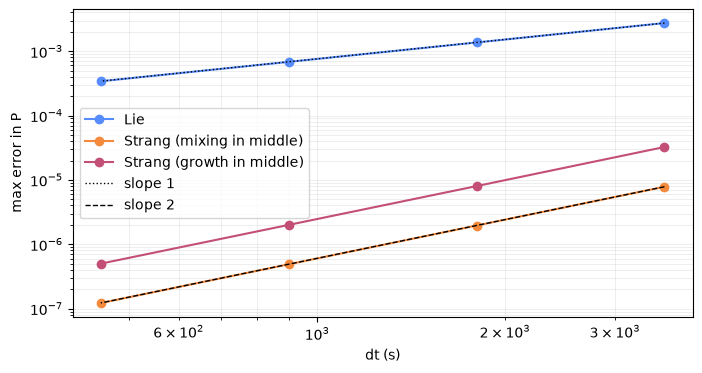

In [5]:
LIE      = [("growth", 1), ("sinking", 1), ("mixing", 1)]
STRANG   = [("growth", .5), ("sinking", .5), ("mixing", 1), ("sinking", .5), ("growth", .5)]
STRANG_B = [("mixing", .5), ("sinking", .5), ("growth", 1), ("sinking", .5), ("mixing", .5)]

def final_P(dt, splitting):
    return sim.run(DT_SECONDS=dt, T_END_DAYS=5, SAVE_EVERY_DAYS=5,
                   SPLITTING=splitting, SINKING_ENABLED=True).P[-1]

ref = final_P(11.25, STRANG)
dts = np.array([3600, 1800, 900, 450])
errors = {name: np.array([abs(final_P(dt, s) - ref).max() for dt in dts])
          for name, s in (("Lie", LIE), ("Strang (mixing in middle)", STRANG), ("Strang (growth in middle)", STRANG_B))}

for name, e in errors.items():
    print(f"{name:28s} errors {np.array2string(e, formatter={'float_kind': lambda x: f'{x:.2e}'})}   observed orders {np.round(np.log2(e[:-1] / e[1:]), 2)}")

fig, ax = plt.subplots()
for name, e in errors.items():
    ax.loglog(dts, e, "o-", label=name)
ax.loglog(dts, errors["Lie"][0] * dts / dts[0], "k:", lw=1, label="slope 1")
ax.loglog(dts, errors["Strang (mixing in middle)"][0] * (dts / dts[0]) ** 2, "k--", lw=1, label="slope 2")
ax.set_xlabel("dt (s)"); ax.set_ylabel("max error in P"); ax.legend(); ax.grid(True, which="both", alpha=.3)
plt.show()

## 5. How deep must the column be?

The model uses a finite depth with a fixed bottom value, standing in for z → −∞. Compare a 250 m and a 500 m column
(same grid spacing) over three years, looking only at the upper 250 m. If they disagree, the bottom is too close.

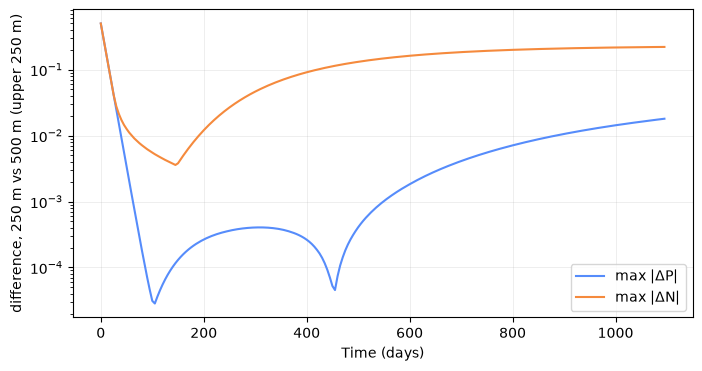

final-time difference: P 1.80e-02, N 2.21e-01


In [6]:
long = dict(T_END_DAYS=3 * 365, SAVE_EVERY_DAYS=5, SINKING_ENABLED=True, N_BOT_BC="dirichlet")
shallow = sim.run(DEPTH=250, NZ=64, **long)
deep = sim.run(DEPTH=500, NZ=127, **long)

n = len(shallow.depth)                                    # the upper 250 m of the deep column
dP = abs(deep.P[:, -n:] - shallow.P).max(axis=1)
dN = abs(deep.N[:, -n:] - shallow.N).max(axis=1)

fig, ax = plt.subplots()
ax.semilogy(shallow.days, dP, label="max |ΔP|"); ax.semilogy(shallow.days, dN, label="max |ΔN|")
ax.set_xlabel("Time (days)"); ax.set_ylabel("difference, 250 m vs 500 m (upper 250 m)"); ax.legend(); ax.grid(True, alpha=.3)
plt.show()
print(f"final-time difference: P {dP[-1]:.2e}, N {dN[-1]:.2e}")

## 6. Forcing experiments

All runs: 500 m column, fixed bottom N, sinking on, three years. Amplitudes are given as multiples of a reference supply
`F_REF = KAPPA × LIGHT_ATTENUATION` (about the size of the natural upward diffusive nitrogen flux). Nitrogen added at the
surface has no way out except through the bottom, so large forcing accumulates: watch the integrated totals.

* seasonal flux: `sine(0.2·F_REF, 0.2·F_REF, 365, phase_days=-91)` (peaks at day 0)
* seasonal light: `LIGHT_FORCING = sine(1, 0.5, 365, phase_days=-91)` (brightest in mid-year)
* storm pulses: four short pulses
* eutrophication trend: seasonal flux plus a ramp up to `F_REF`

Several forcings in one run are combined with `add(...)`.

In [7]:
F_REF = 1e-4 * 0.05                       # KAPPA * LIGHT_ATTENUATION (m s^-1 in nutrient units)
long = dict(DEPTH=500, NZ=127, T_END_DAYS=3 * 365, SAVE_EVERY_DAYS=5, SINKING_ENABLED=True, N_BOT_BC="dirichlet")

seasonal_flux = sine(0.2 * F_REF, 0.2 * F_REF, 365, phase_days=-91)
runs = {
    "unforced":             sim.run(**long),
    "seasonal flux":        sim.run(SURFACE_FLUX=seasonal_flux, **long),
    "seasonal light":       sim.run(LIGHT_FORCING=sine(1.0, 0.5, 365, phase_days=-91), **long),
    "storm pulses":         sim.run(SURFACE_FLUX=pulses([100, 300, 500, 700], 1e-5, 2.0), **long),
    "eutrophication trend": sim.run(SURFACE_FLUX=add(seasonal_flux, ramp(365, 1095, 0, F_REF)), **long),
}

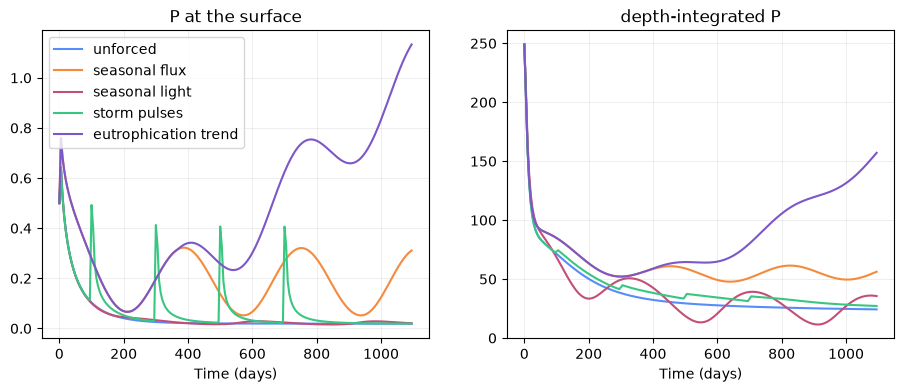

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, res in runs.items():
    ax[0].plot(res.days, res.P[:, -1], label=name)                 # surface P
    ax[1].plot(res.days, trapz(res.P, res.depth, axis=1), label=name)
ax[0].set_title("P at the surface"); ax[1].set_title("depth-integrated P")
for a in ax: a.set_xlabel("Time (days)"); a.grid(True, alpha=.3)
ax[0].legend()
plt.show()

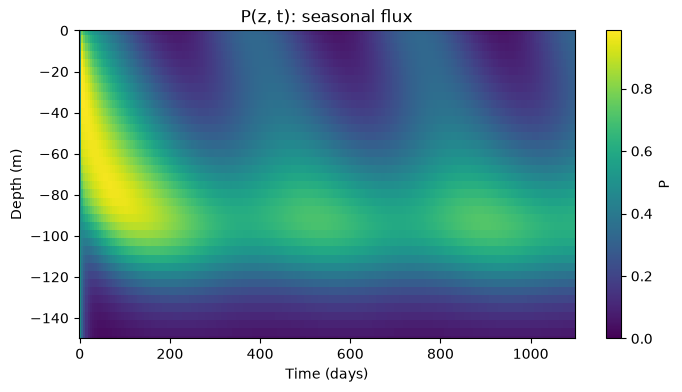

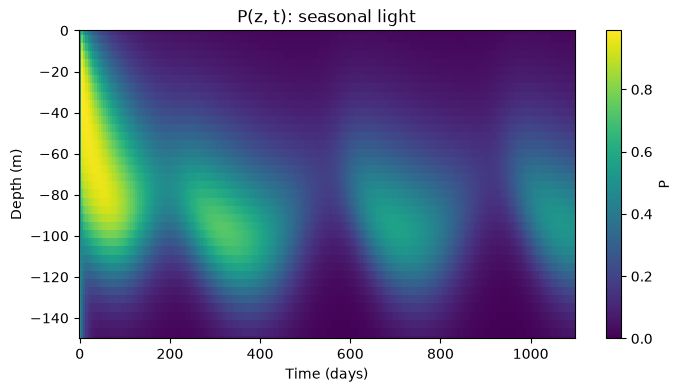

In [9]:
for name in ("seasonal flux", "seasonal light"):
    plots.hovmoller(runs[name], "P", zmin=-150)
    plt.title(f"P(z, t): {name}")
plt.show()

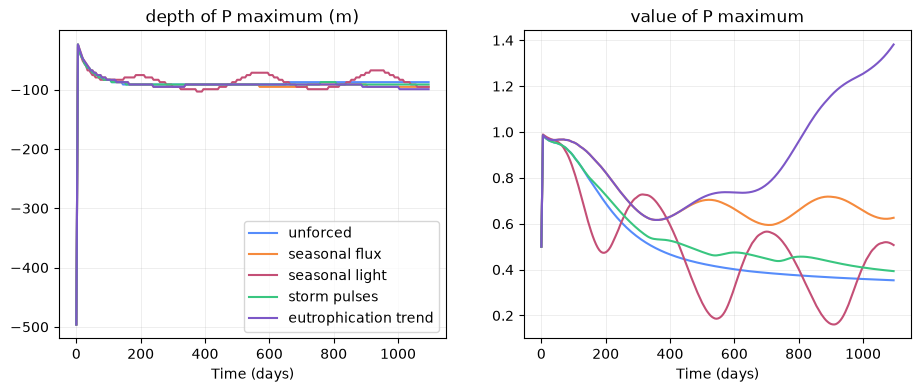

run                    final ∫N     final ∫P
unforced                   472.9      24.3
seasonal flux              535.5      56.3
seasonal light             461.7      35.6
storm pulses               487.4      27.2
eutrophication trend       592.4     157.1


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, res in runs.items():
    d, v = dcm(res)
    ax[0].plot(res.days, d, label=name); ax[1].plot(res.days, v, label=name)
ax[0].set_title("depth of P maximum (m)"); ax[1].set_title("value of P maximum")
for a in ax: a.set_xlabel("Time (days)"); a.grid(True, alpha=.3)
ax[0].legend()
plt.show()

print(f"{'run':22s} final ∫N     final ∫P")
for name, res in runs.items():
    print(f"{name:22s} {trapz(res.N[-1], res.depth):9.1f} {trapz(res.P[-1], res.depth):9.1f}")

## Saving a run you want to keep

Nothing above writes to disk. To keep a run (for slides, or to compare against after a code change):

In [11]:
# sim.run(save_as="data/baseline")                # also writes data/baseline.npz
# baseline = sim.load("data/baseline.npz")        # later: analyse without re-running